In [197]:

import pandas as pd
import numpy as np

DATA_PATH = "data/processed/addis_ababa_rental_training_dataset.csv"

training_df = pd.read_csv(DATA_PATH)

print("\nDataset shape:", training_df.shape)

print("\nRecords per source:")
print(training_df["source"].value_counts())



Dataset shape: (2288, 16)

Records per source:
source
jiji           1939
realethio       142
zegebeya        106
qefira           59
afrotie          28
livingethio      14
Name: count, dtype: int64


In [196]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [198]:

import pandas as pd
import numpy as np

DATA_PATH = "data/processed/addis_ababa_rental_training_dataset.csv"

training_df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("DATASET READINESS AUDIT")
print("=" * 70)

# 1. Basic structure
print("\n1. DATASET STRUCTURE")
print("Shape:", training_df.shape)
print("\nData types:")
print(training_df.dtypes)

# 2. Target validation
target = "monthly_rent_etb"

print("\n2. TARGET VALIDATION")
print("Missing targets:", training_df[target].isna().sum())
print("Non-positive targets:", (training_df[target] <= 0).sum())
print("\nTarget statistics:")
print(training_df[target].describe())

# 3. Source distribution
print("\n3. RECORDS BY SOURCE")
print(training_df["source"].value_counts())

print("\nRENT STATISTICS BY SOURCE")
print(
    training_df.groupby("source")[target]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("count", ascending=False)
    .round(2)
)

# 4. Area unit audit
print("\n4. AREA UNIT DISTRIBUTION")
print(training_df["area_unit"].value_counts(dropna=False))

print("\nAREA SUMMARY BY UNIT")
print(
    training_df.groupby("area_unit", dropna=False)["area"]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

# 5. Missing values
print("\n5. MISSING VALUES")
missing = training_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing if not missing.empty else "No missing values.")

# 6. Potentially extreme rents
print("\n6. HIGHEST 20 MONTHLY RENTS")
columns_to_show = [
    "source", "listing_id", "title", "location",
    "monthly_rent_etb", "area", "area_unit",
    "bedrooms", "bathrooms"
]

print(
    training_df.nlargest(20, target)[columns_to_show]
    .to_string(index=False)
)

# 7. Very low rents
print("\n7. LOWEST 20 MONTHLY RENTS")
print(
    training_df.nsmallest(20, target)[columns_to_show]
    .to_string(index=False)
)

# 8. Duplicate identifiers
print("\n8. DUPLICATE IDENTIFIER CHECK")
print("Duplicate record_id:", training_df["record_id"].duplicated().sum())
print("Duplicate source + listing_id:",
      training_df.duplicated(["source", "listing_id"]).sum())

print("\nAUDIT COMPLETE — NO RECORDS WERE MODIFIED.")


DATASET READINESS AUDIT

1. DATASET STRUCTURE
Shape: (2288, 16)

Data types:
record_id               str
source                  str
listing_id              str
title                   str
property_type           str
location                str
bedrooms            float64
bathrooms           float64
area                float64
area_unit               str
furnished               str
condition               str
date_published          str
latitude            float64
longitude           float64
monthly_rent_etb    float64
dtype: object

2. TARGET VALIDATION
Missing targets: 0
Non-positive targets: 0

Target statistics:
count    2.288000e+03
mean     9.825724e+04
std      8.404023e+04
min      9.000000e+02
25%      4.200000e+04
50%      8.000000e+04
75%      1.300000e+05
max      1.300000e+06
Name: monthly_rent_etb, dtype: float64

3. RECORDS BY SOURCE
source
jiji           1939
realethio       142
zegebeya        106
qefira           59
afrotie          28
livingethio      14
Name: count,

EXPLORATORY DATA ANALYSIS

1. TARGET DISTRIBUTION
count       2288.00
mean       98257.24
std        84040.23
min          900.00
25%        42000.00
50%        80000.00
75%       130000.00
max      1300000.00
Name: monthly_rent_etb, dtype: float64

Skewness: 3.304
Kurtosis: 26.439


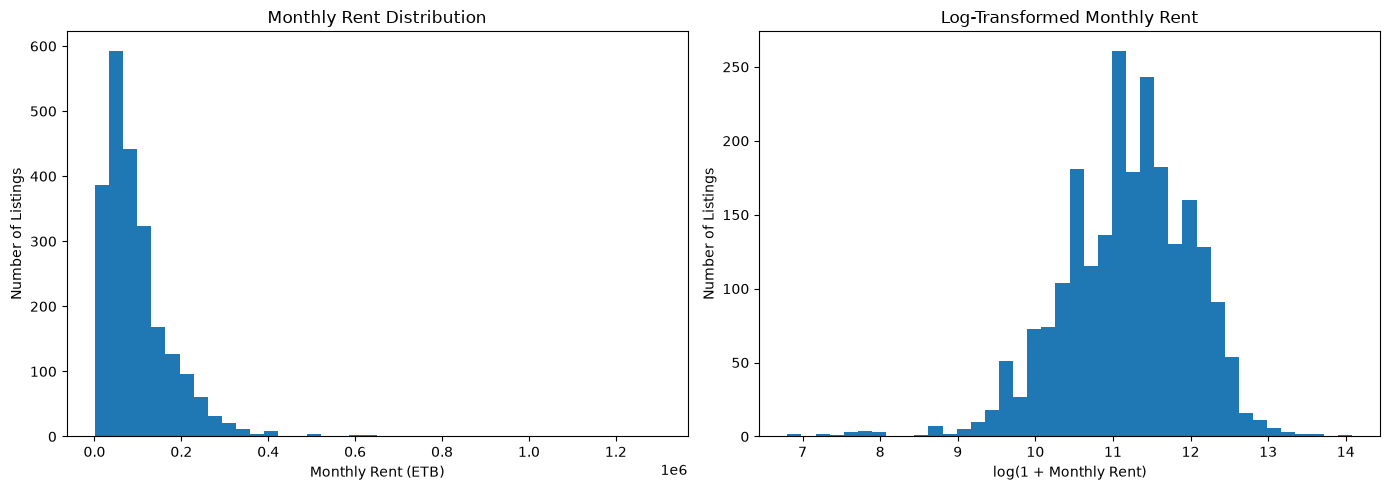


2. RENT BY SOURCE
             count    median       mean        std
source                                            
afrotie         28   61000.0  108928.57  149580.38
jiji          1939   70000.0   90893.77   74559.66
livingethio     14   85000.0   93071.43   47716.65
qefira          59   95000.0  110711.02   73061.11
realethio      142   92500.0  124485.92  132319.34
zegebeya       106  183500.0  188750.94   91721.22


<Figure size 1200x600 with 0 Axes>

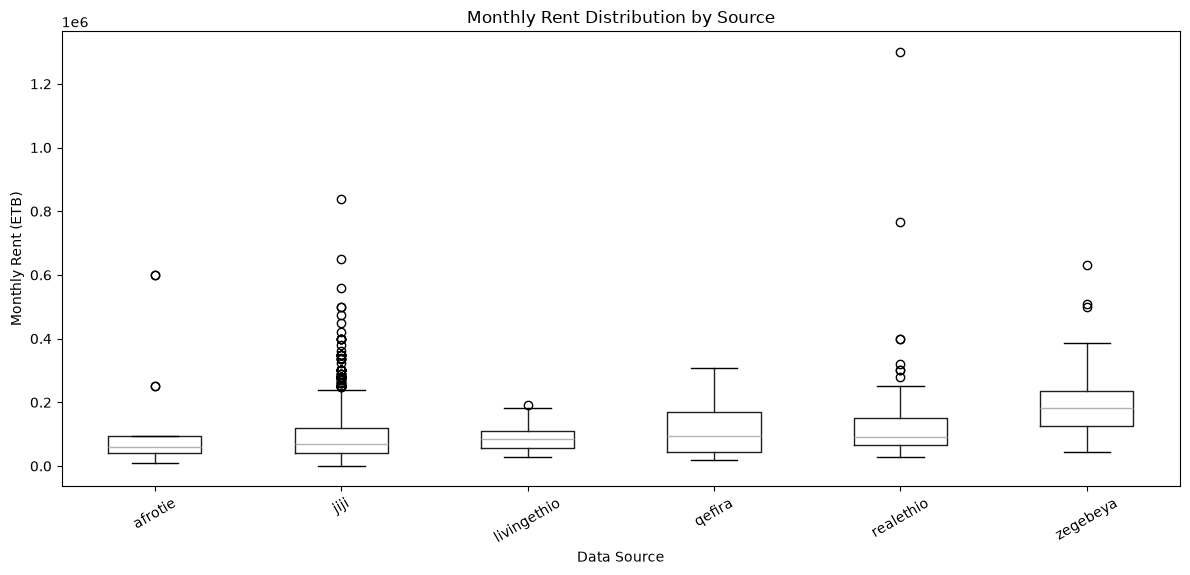


3. PROPERTY TYPE DISTRIBUTION
property_type
Apartment                                               1317
House                                                    362
Condo                                                     95
Apartment for rent                                        79
Villa                                                     66
House for rent                                            54
Studio Apartment                                          33
Apartments for Rent                                       33
Penthouse                                                 29
Houses for Rent                                           26
Houses, Residential, Villa                                26
Houses, Residential                                       21
NaN                                                       20
Apartments, Furnished Apartment, Residential              17
Townhouse / Terrace                                       15
Duplex                                  

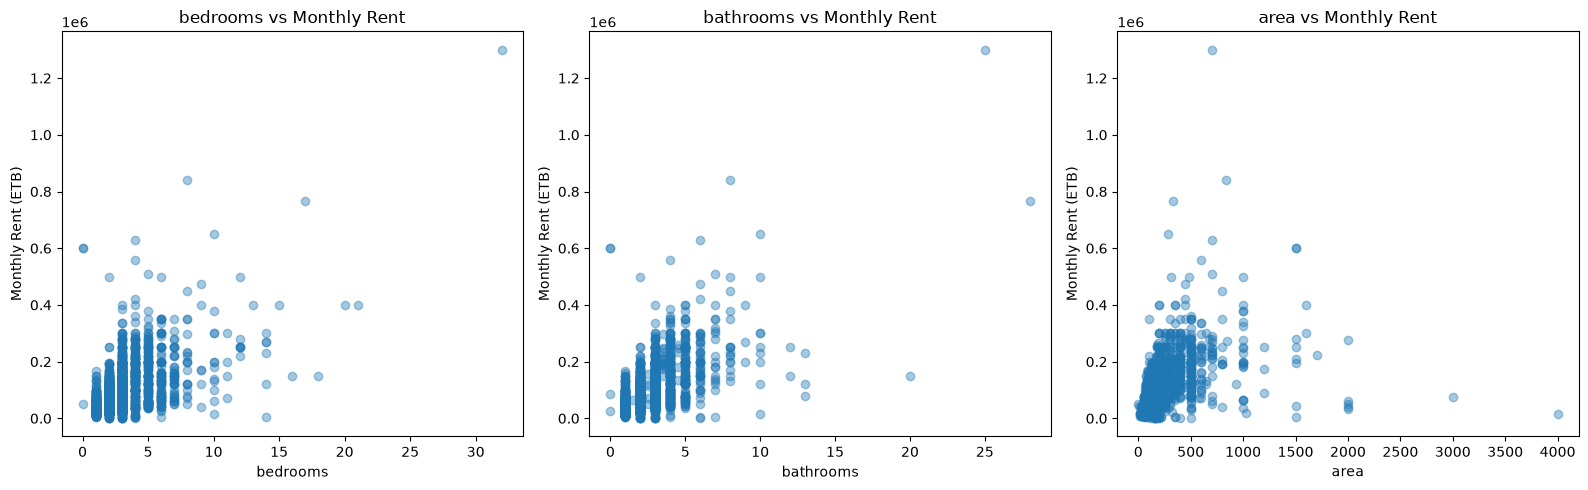


5. MISSING VALUE PERCENTAGES
furnished         93.18
latitude          89.16
longitude         89.16
condition         15.25
area               2.62
title              1.22
date_published     1.22
property_type      0.87
bathrooms          0.66
location           0.52
bedrooms           0.09
dtype: float64

6. AREA UNITS BY SOURCE
area_unit    sqft   sqm  unknown   All
source                                
afrotie         0     0       28    28
jiji            0  1939        0  1939
livingethio     0    14        0    14
qefira         30     0       29    59
realethio       0   142        0   142
zegebeya        0    87       19   106
All            30  2182       76  2288

Area statistics by source and unit:
                       count  median    min     max
source      area_unit                              
afrotie     unknown       28   110.0    0.0  1500.0
jiji        sqm         1939   140.0   10.0  4000.0
livingethio sqm            1   330.0  330.0   330.0
qefira      sqft  

In [200]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = training_df.copy()

target = "monthly_rent_etb"

print("=" * 70)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# --------------------------------------------------
# 1. Target distribution
# --------------------------------------------------

print("\n1. TARGET DISTRIBUTION")

print(df[target].describe().round(2))

print("\nSkewness:", round(df[target].skew(), 3))
print("Kurtosis:", round(df[target].kurtosis(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df[target], bins=40)
axes[0].set_title("Monthly Rent Distribution")
axes[0].set_xlabel("Monthly Rent (ETB)")
axes[0].set_ylabel("Number of Listings")

axes[1].hist(np.log1p(df[target]), bins=40)
axes[1].set_title("Log-Transformed Monthly Rent")
axes[1].set_xlabel("log(1 + Monthly Rent)")
axes[1].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 2. Rent distribution by source
# --------------------------------------------------

print("\n2. RENT BY SOURCE")

source_stats = (
    df.groupby("source")[target]
    .agg(["count", "median", "mean", "std"])
    .round(2)
)

print(source_stats)

source_order = (
    df.groupby("source")[target]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(12, 6))

df.boxplot(
    column=target,
    by="source",
    grid=False,
    rot=30,
    figsize=(12, 6)
)

plt.title("Monthly Rent Distribution by Source")
plt.suptitle("")
plt.xlabel("Data Source")
plt.ylabel("Monthly Rent (ETB)")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. Rent by property type
# --------------------------------------------------

print("\n3. PROPERTY TYPE DISTRIBUTION")

print(df["property_type"].value_counts(dropna=False).head(20))

property_medians = (
    df.groupby("property_type", dropna=False)[target]
    .agg(["count", "median"])
    .sort_values("count", ascending=False)
)

print("\nRent by property type:")
print(property_medians.head(20).round(2))

# --------------------------------------------------
# 4. Rent versus numerical features
# --------------------------------------------------

print("\n4. NUMERICAL FEATURE RELATIONSHIPS")

numerical_features = ["bedrooms", "bathrooms", "area"]

print(df[numerical_features + [target]].corr().round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, numerical_features):
    ax.scatter(
        df[feature],
        df[target],
        alpha=0.4
    )
    ax.set_title(f"{feature} vs Monthly Rent")
    ax.set_xlabel(feature)
    ax.set_ylabel("Monthly Rent (ETB)")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. Missing values
# --------------------------------------------------

print("\n5. MISSING VALUE PERCENTAGES")

missing_pct = (
    df.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(missing_pct[missing_pct > 0].round(2))

# --------------------------------------------------
# 6. Area units by source
# --------------------------------------------------

print("\n6. AREA UNITS BY SOURCE")

print(
    pd.crosstab(
        df["source"],
        df["area_unit"],
        margins=True
    )
)

print("\nArea statistics by source and unit:")

print(
    df.groupby(["source", "area_unit"], dropna=False)["area"]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

# --------------------------------------------------
# 7. Categorical feature cardinality
# --------------------------------------------------

print("\n7. CATEGORICAL FEATURE CARDINALITY")

categorical_features = [
    "property_type",
    "location",
    "furnished",
    "condition"
]

for feature in categorical_features:
    print(
        f"{feature}: "
        f"{df[feature].nunique(dropna=True)} unique values"
    )

print("\nEDA COMPLETE — NO RECORDS WERE MODIFIED.")


In [201]:

# Focused feature-quality audit

df = training_df.copy()

print("=" * 70)
print("FEATURE QUALITY AUDIT")
print("=" * 70)

# 1. Area units by source
print("\n1. AREA UNITS BY SOURCE")

print(pd.crosstab(
    df["source"],
    df["area_unit"],
    margins=True
))

# 2. Missing values in proposed features
features = [
    "property_type",
    "location",
    "bedrooms",
    "bathrooms",
    "area",
    "furnished",
    "condition"
]

print("\n2. MISSING VALUES IN PROPOSED FEATURES")

print(
    df[features]
    .isna()
    .sum()
    .to_frame("missing_count")
    .assign(
        missing_percentage=lambda x:
        (x["missing_count"] / len(df) * 100).round(2)
    )
)

# 3. Categorical cardinality
categorical = [
    "property_type",
    "location",
    "furnished",
    "condition"
]

print("\n3. CATEGORICAL CARDINALITY")

for col in categorical:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts(dropna=False).head(15))

# 4. Low-rent listings for currency review
print("\n4. LISTINGS WITH RENT <= 5,000 ETB")

print(
    df[df["monthly_rent_etb"] <= 5000][
        [
            "source",
            "listing_id",
            "title",
            "monthly_rent_etb",
            "area",
            "bedrooms"
        ]
    ].to_string(index=False)
)

print("\nFEATURE QUALITY AUDIT COMPLETE.")


FEATURE QUALITY AUDIT

1. AREA UNITS BY SOURCE
area_unit    sqft   sqm  unknown   All
source                                
afrotie         0     0       28    28
jiji            0  1939        0  1939
livingethio     0    14        0    14
qefira         30     0       29    59
realethio       0   142        0   142
zegebeya        0    87       19   106
All            30  2182       76  2288

2. MISSING VALUES IN PROPOSED FEATURES
               missing_count  missing_percentage
property_type             20                0.87
location                  12                0.52
bedrooms                   2                0.09
bathrooms                 15                0.66
area                      60                2.62
furnished               2132               93.18
condition                349               15.25

3. CATEGORICAL CARDINALITY

property_type: 41 unique values
property_type
Apartment                                       1317
House                                     

In [202]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Start from the consolidated dataset
df = training_df.copy().reset_index(drop=True)

# Initial feature set
feature_columns = [
    "property_type",
    "location",
    "bedrooms",
    "bathrooms",
    "condition"
]

target_column = "monthly_rent_etb"

# --------------------------------------------------
# 1. Create temporary target bins for stratification
# --------------------------------------------------

df["rent_stratum"] = pd.qcut(
    df[target_column],
    q=10,
    labels=False,
    duplicates="drop"
)

print("Number of target strata:", df["rent_stratum"].nunique())
print("\nRecords per target stratum:")
print(df["rent_stratum"].value_counts().sort_index())

# --------------------------------------------------
# 2. First split: 70% training, 30% temporary
# --------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["rent_stratum"]
)

# --------------------------------------------------
# 3. Second split: 15% validation, 15% test
# --------------------------------------------------

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["rent_stratum"]
)

# --------------------------------------------------
# 4. Separate predictors and target
# --------------------------------------------------

X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_validation = validation_df[feature_columns].copy()
y_validation = validation_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

# --------------------------------------------------
# 5. Remove temporary stratification column
# --------------------------------------------------

train_df = train_df.drop(columns=["rent_stratum"])
validation_df = validation_df.drop(columns=["rent_stratum"])
test_df = test_df.drop(columns=["rent_stratum"])

# --------------------------------------------------
# 6. Verify split sizes
# --------------------------------------------------

print("\n" + "=" * 65)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 65)

print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(validation_df) + len(test_df))

# --------------------------------------------------
# 7. Compare target distributions
# --------------------------------------------------

print("\nTARGET DISTRIBUTION BY SPLIT")

split_summary = pd.DataFrame({
    "training": y_train.describe(),
    "validation": y_validation.describe(),
    "test": y_test.describe()
})

print(split_summary.round(2))

# --------------------------------------------------
# 8. Check source representation
# --------------------------------------------------

print("\nSOURCE DISTRIBUTION BY SPLIT")

source_distribution = pd.concat(
    [
        train_df["source"].value_counts(normalize=True).rename("training"),
        validation_df["source"].value_counts(normalize=True).rename("validation"),
        test_df["source"].value_counts(normalize=True).rename("test")
    ],
    axis=1
).fillna(0) * 100

print(source_distribution.round(2))

# --------------------------------------------------
# 9. Check for identifier overlap
# --------------------------------------------------

train_ids = set(train_df["record_id"])
validation_ids = set(validation_df["record_id"])
test_ids = set(test_df["record_id"])

print("\nIDENTIFIER OVERLAP")
print("Train / validation:", len(train_ids & validation_ids))
print("Train / test:", len(train_ids & test_ids))
print("Validation / test:", len(validation_ids & test_ids))

print("\nSPLIT COMPLETE.")


Number of target strata: 10

Records per target stratum:
rent_stratum
0    260
1    219
2    283
3    162
4    311
5    149
6    221
7    279
8    208
9    196
Name: count, dtype: int64

TRAIN / VALIDATION / TEST SPLIT
Training: 1601
Validation: 343
Test: 344
Total: 2288

TARGET DISTRIBUTION BY SPLIT
        training  validation        test
count    1601.00      343.00      344.00
mean    98080.94    97082.46   100249.13
std     80099.15    80237.50   103628.54
min       900.00     1000.00     1500.00
25%     43000.00    44000.00    40000.00
50%     80000.00    75000.00    80000.00
75%    130000.00   124000.00   125500.00
max    840000.00   650000.00  1300000.00

SOURCE DISTRIBUTION BY SPLIT
             training  validation   test
source                                  
jiji            84.38       84.84  86.34
realethio        6.06        6.41   6.69
zegebeya         4.87        4.96   3.20
qefira           2.81        1.75   2.33
afrotie          1.31        1.46   0.58
livingethio 

In [204]:

import pandas as pd
import numpy as np
import sklearn

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Scikit-learn version:", sklearn.__version__)

# --------------------------------------------------
# 1. Prepare feature values
# --------------------------------------------------

categorical_features = [
    "property_type",
    "location",
    "condition"
]

numerical_features = [
    "bedrooms",
    "bathrooms"
]

feature_columns = categorical_features + numerical_features


def normalize_property_type(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if "studio" in value:
        return "Studio Apartment"

    if "apartment" in value and "house" in value:
        return "Mixed residential"

    if "villa" in value:
        return "Villa"

    if "penthouse" in value:
        return "Penthouse"

    if "townhouse" in value or "terrace" in value:
        return "Townhouse"

    if "duplex" in value:
        return "Duplex"

    if "mansion" in value:
        return "Mansion"

    if "condo" in value:
        return "Condo"

    if "apartment" in value:
        return "Apartment"

    if "house" in value:
        return "House"

    if "building" in value:
        return "Building"

    if "residential" in value:
        return "Residential"

    return "Other"



def prepare_features(X):
    X = X[feature_columns].copy()

    # Normalize property types
    X["property_type"] = (
        X["property_type"]
        .apply(normalize_property_type)
        .astype(object)
    )

    # Convert categorical columns to ordinary Python strings.
    # Replace all missing values with np.nan.
    for col in ["location", "condition"]:
        X[col] = (
            X[col]
            .astype(object)
            .where(X[col].notna(), np.nan)
        )

        X[col] = X[col].apply(
            lambda value: (
                str(value).strip().lower()
                if pd.notna(value)
                else np.nan
            )
        )

    # Ensure numerical columns contain proper numeric values
    for col in numerical_features:
        X[col] = pd.to_numeric(
            X[col],
            errors="coerce"
        )

    return X


# Recreate prepared features
X_train_prepared = prepare_features(X_train)
X_validation_prepared = prepare_features(X_validation)

print("Training dtypes:")
print(X_train_prepared.dtypes)

print("\nMissing values:")
print(X_train_prepared.isna().sum())

print("\nFeature preparation completed.")



X_train_prepared = prepare_features(X_train)
X_validation_prepared = prepare_features(X_validation)

print("\nTraining feature shape:", X_train_prepared.shape)
print("Validation feature shape:", X_validation_prepared.shape)

# --------------------------------------------------
# 2. Build preprocessing pipelines
# --------------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=5
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
)

# --------------------------------------------------
# 3. Define regression algorithms
# --------------------------------------------------

algorithms = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# --------------------------------------------------
# 4. Train and evaluate on validation data
# --------------------------------------------------

results = []
trained_models = {}

for algorithm_name, algorithm in algorithms.items():

    for target_mode in ["original", "log"]:

        model_pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm)
        ])

        if target_mode == "log":
            model = TransformedTargetRegressor(
                regressor=model_pipeline,
                func=np.log1p,
                inverse_func=np.expm1
            )
        else:
            model = model_pipeline

        model.fit(X_train_prepared, y_train)

        predictions = model.predict(X_validation_prepared)

        mae = mean_absolute_error(
            y_validation,
            predictions
        )

        mse = mean_squared_error(
            y_validation,
            predictions
        )

        rmse = np.sqrt(mse)

        r2 = r2_score(
            y_validation,
            predictions
        )

        experiment_name = f"{algorithm_name} ({target_mode})"

        results.append({
            "model": experiment_name,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2
        })

        trained_models[experiment_name] = model

        print(
            f"Completed: {experiment_name} | "
            f"MAE: {mae:,.2f} | "
            f"RMSE: {rmse:,.2f} | "
            f"R2: {r2:.4f}"
        )

# --------------------------------------------------
# 5. Compare model performance
# --------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 75)
print("VALIDATION RESULTS — MODELS RANKED BY RMSE")
print("=" * 75)

print(results_df.round(3).to_string(index=False))

results_df.to_csv(
    "data/processed/baseline_model_comparison.csv",
    index=False
)

print("\nResults saved to data/processed/baseline_model_comparison.csv")
print("The test set has not been used.")


Scikit-learn version: 1.9.1
Training dtypes:
property_type     object
location             str
condition            str
bedrooms         float64
bathrooms        float64
dtype: object

Missing values:
property_type     15
location           7
condition        250
bedrooms           1
bathrooms         12
dtype: int64

Feature preparation completed.

Training feature shape: (1601, 5)
Validation feature shape: (343, 5)
Completed: Linear Regression (original) | MAE: 41,166.60 | RMSE: 60,908.51 | R2: 0.4221
Completed: Linear Regression (log) | MAE: 38,388.16 | RMSE: 63,067.30 | R2: 0.3804
Completed: Decision Tree (original) | MAE: 43,859.94 | RMSE: 66,730.67 | R2: 0.3063
Completed: Decision Tree (log) | MAE: 42,667.41 | RMSE: 65,879.34 | R2: 0.3239
Completed: Random Forest (original) | MAE: 39,993.84 | RMSE: 59,242.79 | R2: 0.4533
Completed: Random Forest (log) | MAE: 40,155.82 | RMSE: 62,513.68 | R2: 0.3912
Completed: Gradient Boosting (original) | MAE: 39,844.90 | RMSE: 59,160.95 | R2: 0

In [205]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

diagnostics = []

for model_name, model in trained_models.items():

    # Predictions on training data
    train_predictions = model.predict(X_train_prepared)

    # Predictions on validation data
    validation_predictions = model.predict(X_validation_prepared)

    # Training metrics
    train_mae = mean_absolute_error(
        y_train, train_predictions
    )
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )
    train_r2 = r2_score(y_train, train_predictions)

    # Validation metrics
    validation_mae = mean_absolute_error(
        y_validation, validation_predictions
    )
    validation_rmse = np.sqrt(
        mean_squared_error(y_validation, validation_predictions)
    )
    validation_r2 = r2_score(
        y_validation, validation_predictions
    )

    diagnostics.append({
        "Model": model_name,
        "Train MAE": train_mae,
        "Validation MAE": validation_mae,
        "Train RMSE": train_rmse,
        "Validation RMSE": validation_rmse,
        "RMSE Gap": validation_rmse - train_rmse,
        "Train R2": train_r2,
        "Validation R2": validation_r2
    })

diagnostics_df = pd.DataFrame(diagnostics).sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("=" * 110)
print("TRAINING VS VALIDATION PERFORMANCE")
print("=" * 110)

print(diagnostics_df.round(3).to_string(index=False))

diagnostics_df.to_csv(
    "data/processed/overfitting_diagnostics.csv",
    index=False
)

TRAINING VS VALIDATION PERFORMANCE
                       Model  Train MAE  Validation MAE  Train RMSE  Validation RMSE  RMSE Gap  Train R2  Validation R2
Gradient Boosting (original)  36939.030       39844.904   52132.319        59160.952  7028.633     0.576          0.455
    Random Forest (original)  31502.440       39993.835   47269.470        59242.791 11973.321     0.652          0.453
Linear Regression (original)  37841.192       41166.601   57600.522        60908.514  3307.992     0.483          0.422
     Gradient Boosting (log)  37442.984       39308.427   58319.289        62490.865  4171.576     0.470          0.392
         Random Forest (log)  31501.964       40155.820   52325.484        62513.684 10188.201     0.573          0.391
     Linear Regression (log)  37742.281       38388.160   65971.439        63067.296 -2904.143     0.321          0.380
         Decision Tree (log)  36866.515       42667.407   59046.567        65879.340  6832.773     0.456          0.324
    D

In [206]:
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.pipeline import Pipeline

# Five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Gradient Boosting search space
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        random_state=42
    ))
])

gb_parameters = {
    "regressor__n_estimators": [100, 150, 200, 300],
    "regressor__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "regressor__max_depth": [2, 3, 4],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [2, 5, 10],
    "regressor__subsample": [0.7, 0.85, 1.0],
    "regressor__max_features": [None, "sqrt", 0.8]
}

# Random Forest search space
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

rf_parameters = {
    "regressor__n_estimators": [200, 300, 500],
    "regressor__max_depth": [None, 10, 15, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [2, 4, 6],
    "regressor__max_features": [1.0, "sqrt", 0.8]
}

print("Cross-validation and parameter spaces configured.")

Cross-validation and parameter spaces configured.


In [207]:
search_spaces = {
    "Gradient Boosting": (
        gb_pipeline,
        gb_parameters
    ),
    "Random Forest": (
        rf_pipeline,
        rf_parameters
    )
}

searches = {}
tuning_results = []

for model_name, (pipeline, parameters) in search_spaces.items():

    print("\n" + "=" * 70)
    print(f"TUNING: {model_name}")
    print("=" * 70)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        random_state=42,
        verbose=1,
        return_train_score=True
    )

    # Only training data is used here.
    search.fit(X_train_prepared, y_train)

    searches[model_name] = search

    best_cv_rmse = -search.best_score_

    tuning_results.append({
        "Model": model_name,
        "Best CV RMSE": best_cv_rmse,
        "Best Parameters": search.best_params_
    })

    print("\nBest cross-validation RMSE:", round(best_cv_rmse, 2))
    print("\nBest parameters:")
    print(search.best_params_)

tuning_results_df = pd.DataFrame(tuning_results)

print("\n" + "=" * 70)
print("HYPERPARAMETER TUNING SUMMARY")
print("=" * 70)

print(
    tuning_results_df[
        ["Model", "Best CV RMSE"]
    ].round(2).to_string(index=False)
)


TUNING: Gradient Boosting
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best cross-validation RMSE: 60746.33

Best parameters:
{'regressor__subsample': 0.85, 'regressor__n_estimators': 300, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 'sqrt', 'regressor__max_depth': 3, 'regressor__learning_rate': 0.03}

TUNING: Random Forest
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best cross-validation RMSE: 61382.43

Best parameters:
{'regressor__n_estimators': 300, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 'sqrt', 'regressor__max_depth': 15}

HYPERPARAMETER TUNING SUMMARY
            Model  Best CV RMSE
Gradient Boosting      60746.33
    Random Forest      61382.43


In [208]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

tuned_validation_results = []
tuned_models = {}

for model_name, search in searches.items():

    best_model = search.best_estimator_
    tuned_models[model_name] = best_model

    # Predict training and validation data
    train_predictions = best_model.predict(X_train_prepared)
    validation_predictions = best_model.predict(X_validation_prepared)

    # Training metrics
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    # Validation metrics
    mae = mean_absolute_error(
        y_validation, validation_predictions
    )
    mse = mean_squared_error(
        y_validation, validation_predictions
    )
    rmse = np.sqrt(mse)
    r2 = r2_score(
        y_validation, validation_predictions
    )

    tuned_validation_results.append({
        "Model": model_name,
        "CV RMSE": -search.best_score_,
        "Train RMSE": train_rmse,
        "Validation MAE": mae,
        "Validation MSE": mse,
        "Validation RMSE": rmse,
        "Validation R2": r2,
        "RMSE Gap": rmse - train_rmse
    })

tuned_validation_df = pd.DataFrame(
    tuned_validation_results
).sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("=" * 110)
print("TUNED MODEL VALIDATION RESULTS")
print("=" * 110)

print(tuned_validation_df.round(3).to_string(index=False))

tuned_validation_df.to_csv(
    "data/processed/tuned_model_validation_results.csv",
    index=False
)

TUNED MODEL VALIDATION RESULTS
            Model   CV RMSE  Train RMSE  Validation MAE  Validation MSE  Validation RMSE  Validation R2  RMSE Gap
Gradient Boosting 60746.330   54742.258       39853.364    3.629017e+09        60241.324          0.435  5499.065
    Random Forest 61382.435   56703.260       40396.561    3.646614e+09        60387.200          0.432  3683.941


In [209]:
baseline_comparison = results_df[
    ["model", "MAE", "RMSE", "R2"]
].copy()

baseline_comparison["Experiment"] = "Baseline"
baseline_comparison = baseline_comparison.rename(
    columns={
        "model": "Model",
        "MAE": "Validation MAE",
        "RMSE": "Validation RMSE",
        "R2": "Validation R2"
    }
)

tuned_comparison = tuned_validation_df[
    ["Model", "Validation MAE", "Validation RMSE", "Validation R2"]
].copy()

tuned_comparison["Experiment"] = "Tuned"

combined_comparison = pd.concat(
    [baseline_comparison, tuned_comparison],
    ignore_index=True
)

combined_comparison = combined_comparison.sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("=" * 100)
print("BASELINE VS TUNED MODEL COMPARISON")
print("=" * 100)

print(combined_comparison.round(3).to_string(index=False))

combined_comparison.to_csv(
    "data/processed/baseline_vs_tuned_comparison.csv",
    index=False
)

BASELINE VS TUNED MODEL COMPARISON
                       Model  Validation MAE  Validation RMSE  Validation R2 Experiment
Gradient Boosting (original)       39844.904        59160.952          0.455   Baseline
    Random Forest (original)       39993.835        59242.791          0.453   Baseline
           Gradient Boosting       39853.364        60241.324          0.435      Tuned
               Random Forest       40396.561        60387.200          0.432      Tuned
Linear Regression (original)       41166.601        60908.514          0.422   Baseline
     Gradient Boosting (log)       39308.427        62490.865          0.392   Baseline
         Random Forest (log)       40155.820        62513.684          0.391   Baseline
     Linear Regression (log)       38388.160        63067.296          0.380   Baseline
         Decision Tree (log)       42667.407        65879.340          0.324   Baseline
    Decision Tree (original)       43859.936        66730.675          0.306   Baseli

In [210]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

selected_model = trained_models["Gradient Boosting (original)"]

validation_predictions = selected_model.predict(
    X_validation_prepared
)

residuals = y_validation.to_numpy() - validation_predictions

residual_df = pd.DataFrame({
    "actual_rent": y_validation.to_numpy(),
    "predicted_rent": validation_predictions,
    "residual": residuals,
    "absolute_error": np.abs(residuals)
})

print("VALIDATION RESIDUAL SUMMARY")
print("=" * 60)

print(residual_df[
    ["actual_rent", "predicted_rent", "residual", "absolute_error"]
].describe().round(2))

print("\nNegative predictions:", (validation_predictions < 0).sum())
print("Mean residual:", round(residuals.mean(), 2))
print("Median residual:", round(np.median(residuals), 2))

VALIDATION RESIDUAL SUMMARY
       actual_rent  predicted_rent   residual  absolute_error
count       343.00          343.00     343.00          343.00
mean      97082.46        92332.88    4749.58        39844.90
std       80237.50        45403.38   59056.14        43794.90
min        1000.00        23518.21 -118401.62         1323.65
25%       44000.00        59319.91  -27439.23        12198.49
50%       75000.00        77732.15   -7732.15        27183.91
75%      124000.00       110471.00   26487.17        51633.60
max      650000.00       311559.32  417625.41       417625.41

Negative predictions: 0
Mean residual: 4749.58
Median residual: -7732.15


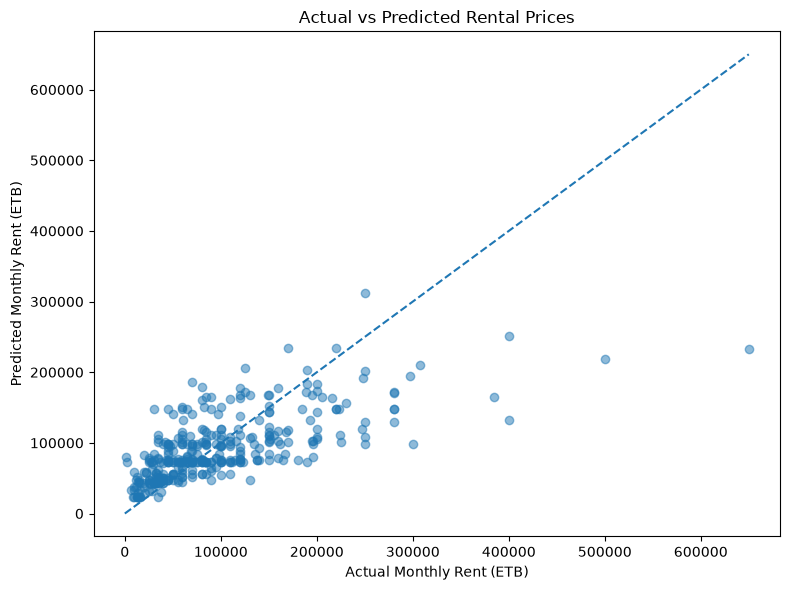

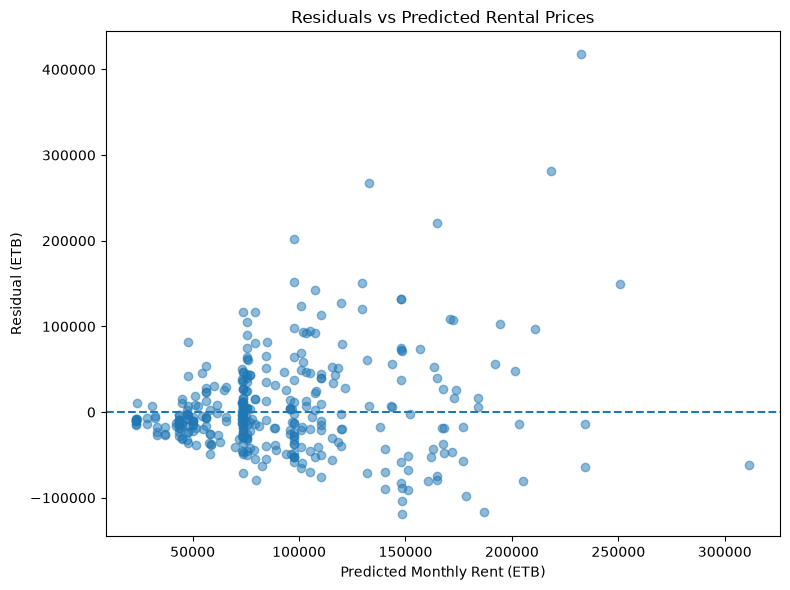

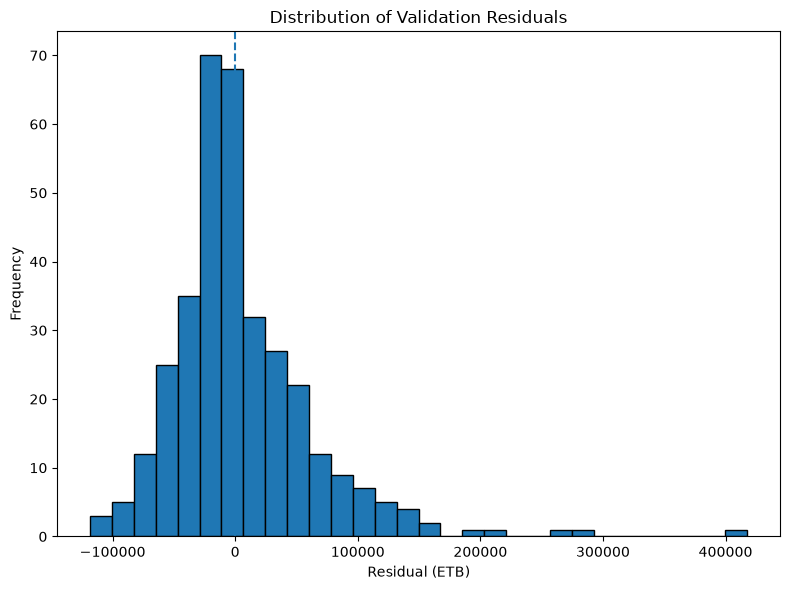

In [211]:
# Plot 1: Actual vs predicted rent
plt.figure(figsize=(8, 6))

plt.scatter(
    residual_df["actual_rent"],
    residual_df["predicted_rent"],
    alpha=0.5
)

max_value = max(
    residual_df["actual_rent"].max(),
    residual_df["predicted_rent"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Monthly Rent (ETB)")
plt.ylabel("Predicted Monthly Rent (ETB)")
plt.title("Actual vs Predicted Rental Prices")
plt.tight_layout()
plt.show()


# Plot 2: Residuals vs predicted rent
plt.figure(figsize=(8, 6))

plt.scatter(
    residual_df["predicted_rent"],
    residual_df["residual"],
    alpha=0.5
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Monthly Rent (ETB)")
plt.ylabel("Residual (ETB)")
plt.title("Residuals vs Predicted Rental Prices")
plt.tight_layout()
plt.show()


# Plot 3: Residual distribution
plt.figure(figsize=(8, 6))

plt.hist(
    residual_df["residual"],
    bins=30,
    edgecolor="black"
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Residual (ETB)")
plt.ylabel("Frequency")
plt.title("Distribution of Validation Residuals")
plt.tight_layout()
plt.show()

In [212]:
residual_df["rent_group"] = pd.qcut(
    residual_df["actual_rent"],
    q=5,
    duplicates="drop"
)

error_by_rent = residual_df.groupby(
    "rent_group",
    observed=True
).agg(
    listing_count=("actual_rent", "count"),
    mean_actual_rent=("actual_rent", "mean"),
    mean_predicted_rent=("predicted_rent", "mean"),
    MAE=("absolute_error", "mean"),
    mean_residual=("residual", "mean")
).reset_index()

print("=" * 100)
print("MODEL ERROR BY ACTUAL RENT RANGE")
print("=" * 100)

print(error_by_rent.round(2).to_string(index=False))

MODEL ERROR BY ACTUAL RENT RANGE
          rent_group  listing_count  mean_actual_rent  mean_predicted_rent      MAE  mean_residual
  (999.999, 35000.0]             72          23375.00             52150.11 29085.81      -28775.11
  (35000.0, 60000.0]             67          49850.75             75771.38 27717.09      -25920.64
  (60000.0, 90000.0]             69          76891.07             91859.97 24905.44      -14968.89
 (90000.0, 150000.0]             75         119870.65            104058.73 31622.48       15811.92
(150000.0, 650000.0]             60         233008.33            144932.41 93756.96       88075.93


In [213]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import joblib
import os
import numpy as np
import pandas as pd

# Prepare the untouched test features
X_test_prepared = prepare_features(X_test)

# Selected model: original Gradient Boosting
final_model = trained_models["Gradient Boosting (original)"]

# Predict test data
test_predictions = final_model.predict(X_test_prepared)

# Calculate test metrics
test_mae = mean_absolute_error(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, test_predictions)

# Compare against a simple mean-prediction baseline
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_prepared, y_train)

dummy_predictions = dummy_model.predict(X_test_prepared)

dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_rmse = np.sqrt(
    mean_squared_error(y_test, dummy_predictions)
)
dummy_r2 = r2_score(y_test, dummy_predictions)

# Print results
print("=" * 75)
print("FINAL TEST SET EVALUATION")
print("=" * 75)

print(f"Test observations: {len(y_test)}")
print(f"MAE:  {test_mae:,.2f} ETB")
print(f"MSE:  {test_mse:,.2f} ETB²")
print(f"RMSE: {test_rmse:,.2f} ETB")
print(f"R²:   {test_r2:.4f}")

print("\n" + "=" * 75)
print("COMPARISON WITH MEAN-PREDICTION BASELINE")
print("=" * 75)

print(f"Dummy MAE:  {dummy_mae:,.2f} ETB")
print(f"Dummy RMSE: {dummy_rmse:,.2f} ETB")
print(f"Dummy R²:   {dummy_r2:.4f}")

print("\n" + "=" * 75)
print("TEST TARGET RANGE")
print("=" * 75)

print(f"Training maximum rent: {y_train.max():,.2f} ETB")
print(f"Test maximum rent:     {y_test.max():,.2f} ETB")
print(f"Negative predictions: {(test_predictions < 0).sum()}")

# Save test predictions for documentation
test_predictions_df = pd.DataFrame({
    "actual_rent_etb": y_test.to_numpy(),
    "predicted_rent_etb": test_predictions,
    "residual_etb": y_test.to_numpy() - test_predictions
})

test_predictions_df.to_csv(
    "data/processed/final_test_predictions.csv",
    index=False
)

# Save the selected trained pipeline
os.makedirs("models", exist_ok=True)

joblib.dump(
    final_model,
    "models/gradient_boosting_rental_price_model.joblib"
)

print("\nTest predictions and selected model saved.")

FINAL TEST SET EVALUATION
Test observations: 344
MAE:  47,272.78 ETB
MSE:  7,021,302,025.57 ETB²
RMSE: 83,793.21 ETB
R²:   0.3443

COMPARISON WITH MEAN-PREDICTION BASELINE
Dummy MAE:  60,847.49 ETB
Dummy RMSE: 103,500.52 ETB
Dummy R²:   -0.0004

TEST TARGET RANGE
Training maximum rent: 840,000.00 ETB
Test maximum rent:     1,300,000.00 ETB
Negative predictions: 0

Test predictions and selected model saved.
